In [1]:
# Optional but good practice if this is your project
using Pkg
Pkg.activate(".")
include("Modules.jl")

using .FunctionTCI


  Activating project at `.`


In [2]:
module VQMLOracle
using LinearAlgebra, Random, Statistics, Yao, Yao.ConstGate

# -------- utilities --------
pow2(n) = 1 << n

"""Single-qubit Rz(θ) = exp(-i θ Z / 2)."""
rz(θ) = ComplexF64[exp(-0.5im*θ) 0; 0 exp(0.5im*θ)]

"""Kronecker of a vector of small matrices (left-to-right order)."""
function kron_all(ms::Vector{<:AbstractMatrix})
    K = Matrix{ComplexF64}(ms[1])
    @inbounds for k in 2:length(ms)
        K = kron(K, Matrix{ComplexF64}(ms[k]))
    end
    return K
end

"""Haar-random unitary of dimension d (QR-based)."""
function haar_unitary(rng::AbstractRNG, d::Int)
    Z = randn(rng, ComplexF64, d, d) .+ 1im*randn(rng, ComplexF64, d, d)
    Q, R = qr(Z); Q = Matrix(Q)
    Λ = Diagonal((diag(R)./abs.(diag(R))) .^ (-1))
    return Q*Λ
end

"""Pauli Z on qubit q (1-based), identity elsewhere, N qubits."""
function Z_on(q::Int, N::Int)
    Z = ComplexF64[1 0; 0 -1]; I = ComplexF64[1 0; 0 1]
    mats = [i==q ? Z : I for i in 1:N]
    return kron_all(mats)
end



# -------- oracle builder --------



"""Sample eigenvalues according to the provided probabilities."""
function sample_eigenvalues(vals::AbstractVector, probs::AbstractVector, shots::Int, rng)
    probs = probs ./ sum(probs)
    edges = cumsum(probs)
    edges[end] = 1.0                     # guard against rounding error
    out = similar(vals, shots)
    for s in 1:shots
        r = rand(rng)
        idx = searchsortedfirst(edges, r)
        out[s] = vals[idx]
    end
    return out
end

"""
make_expectation_evaluator(N, L; W_list=nothing, V_list=nothing, O=:Z1, seed=0, init=:plus)

Returns (fq_exact, W_list, fq_sampled, O_mat), where:
- fq_exact(x)   = exact ⟨O⟩ for |ψ> = (∏ Vₗ(xₗ) Wₗ)|init⟩
- fq_sampled(x, M) = Monte Carlo estimate of ⟨O⟩ using M samples in O’s eigenbasis
"""
function make_fq(
    N::Int, L::Int;
    W_list=nothing, V_list=nothing, O=:Z1, seed=0, init=:zero
)
    d = 2^N
    rng = MersenneTwister(seed)

    O_block = O isa AbstractMatrix ? matblock(O) : O
    O_mat   = O isa AbstractMatrix ? O : mat(O)

    eig = eigen(Hermitian(O_mat))
    eig_vals = real.(eig.values)
    eig_vecs = eig.vectors
    sample_rng = MersenneTwister(seed + 1)  # separate stream for sampling

    # Helper: Haar-random unitary as Yao block
    function haar_unitary_block()
        mat = randn(rng, ComplexF64, d, d) + 1im*randn(rng, ComplexF64, d, d)
        Q, R = qr(mat)
        λ = diag(R)
        phases = λ ./ abs.(λ)
        U = Matrix(Q) * Diagonal(phases .^ (-1))
        matblock(U)
    end

    # Generate or validate W_list: sequence of N-qubit unitaries (Yao blocks)
    _W_list = if W_list === nothing
        [haar_unitary_block() for _ in 1:L]
    else
        length(W_list) == L || error("W_list must have length L")
        W_list
    end

    # Build default V_list: each is a function of x -> N-fold tensor product of Rz gates with those parameters
    function default_V_layer(x::AbstractVector)
        length(x) == N || error("V layer expects N parameters")
        chain([put(N, j=>rot(Z, x[j])) for j=1:N]...)
    end

    # Each V_list[k] should be a function of xk (N-vector) to a Yao N-qubit block.
    _V_list = if V_list === nothing
        [default_V_layer for _ in 1:L]
    else
        length(V_list) == L || error("V_list must have length L")
        V_list
    end

    # Initial state
    ψ0 = if init === :plus
        H_all = chain([put(N, j=>H) for j=1:N]...)
        apply(zero_state(N), H_all)
    elseif init === :zero
        zero_state(N)
    else
        error("init must be :plus or :zero")
    end

    function evolve_state(x::AbstractVector)
        length(x) == N*L || error("Input vector x must have length N*L")
        ψ = copy(ψ0)
        for ℓ in 1:L
            idxs = (ℓ-1)*N+1 : ℓ*N
            ψ = apply(ψ, _W_list[ℓ])
            ψ = apply(ψ, _V_list[ℓ](view(x, idxs)))
        end
        return ψ
    end

    # Exact expectation value
    function eval_exp(x::AbstractVector)
        ψ = evolve_state(x)
        real(expect(O_block, ψ))
    end

    # Monte Carlo estimate of ⟨O⟩ using M projective measurements in O’s eigenbasis
    function eval_sampled(x::AbstractVector, M::Int)
        M > 0 || error("M must be positive")
        ψ = evolve_state(x)
        ψvec = vec(state(ψ))
        amps = eig_vecs' * ψvec
        probs = abs2.(amps)
        outcomes = sample_eigenvalues(eig_vals, probs, M, sample_rng)
        mean(outcomes)
    end

    return eval_exp, eval_sampled, _W_list, O_mat
end


"""
make_fq_noisy(N, L; W_list=nothing, O=:Z1, seed=0, init=:plus, delta=1e-3)

Returns (fq_noisy, W_list, O, info).

Same as make_fq, but fq_noisy(phis) returns fq(phis) + η, where η ~ Normal(0, sqrt(delta)).
"""
function make_fq_noisy(N::Int, L::Int; W_list=nothing, O=:Z1, seed=0, init=:plus, delta=1e-4)
    fq, W, O_mat, info = make_fq(N, L; W_list=W_list, O=O, seed=seed, init=init)
    rng = MersenneTwister(seed + 123456)  # offset to avoid correlation with main rng
    function fq_noisy(phis::AbstractVector{<:Real})
        val = fq(phis)
        noise = sqrt(delta) * randn(rng)
        return val + noise
    end
    return fq_noisy, fq, W, O_mat, info
end

end # module





Main.VQMLOracle

In [ ]:
import TensorCrossInterpolation as TCI
using LinearAlgebra, Random
using Statistics
using Plots

# ---------- 2-norm (Frobenius) relative error on the grid ----------
"""
relerr_grid_2norm(f_idx, dims, cores_F; nsamples=10_000, seed=0, exact_limit=100_000)

Returns ‖F - F̂‖₂ / ‖F‖₂ where F is the dense tensor of f_idx over the full grid
and F̂ is dense_from_tt(cores_F).

- Exact if prod(dims) ≤ exact_limit (default 100_000).
- Otherwise uses Monte-Carlo with nsamples uniformly random grid points.
"""
function relerr_grid_2norm(f_idx, dims::AbstractVector{<:Int}, cores_F;
                           nsamples::Int=10_000, seed::Int=0, exact_limit::Int=100_000)
    total = prod(dims)
    if total <= exact_limit
        # exact
        F  = zeros(Float64, dims...)
        It = Iterators.product((1:d for d in dims)...)
        for I in It
            F[I...] = f_idx(collect(I))
        end
        Fhat = dense_from_tt(cores_F)
        num = norm(F .- Fhat)
        den = max(norm(F), eps())
        return num/den
    else
        # MC estimate of Frobenius error
        rng = MersenneTwister(seed)

        sample_idx() = [rand(rng, 1:d) for d in dims]
        
        # Evaluate TT(F) at a multi-index I without forming the dense tensor
        function ttF_eval(cores_F, I::Vector{Int})
            v = vec(@view cores_F[1][1, I[1], :])   # (r1,)
            for p in 2:length(cores_F)
                Gp = Matrix(@view cores_F[p][:, I[p], :])  # (r_{p-1}, r_p)
                v  = Gp' * v                              # (r_p,)
            end
            return float(v[1])
        end
        num2 = 0.0; den2 = 0.0
        for _ in 1:nsamples
            I = sample_idx()
            y  = f_idx(I)
            yh = ttF_eval(cores_F, I)
            num2 += (y - yh)^2
            den2 += y^2
        end
        # scale from sample average to Frobenius by total/nsamples cancels in ratio
        return sqrt(num2)/max(sqrt(den2), eps())
    end
end

"""
compare_and_plot(fq, cores_C, t, D; M=300, seed=0, savepath=nothing)

- D is the dimension of the input
- Draws M random x ∈ [-π,π]^D
- Plots oracle F(φ) and TCI approximation F̂(φ) vs sample index
- Prints RMSE and max error; saves PNG if savepath provided
"""
function compare_and_plot(fq, cores_C, t, D; pair_edges =nothing, M::Int=300, seed::Int=0, savepath=nothing)
    rng = MersenneTwister(seed)
    
    xs = (2π .* rand(rng, M, D))   # each row a φ-vector (feature vector)

    y_true = [fq(@view xs[i, :]) for i in 1:M]
    y_hat  = [eval_from_ttC(cores_C, t, @view xs[i, :]) for i in 1:M]

    rmse   = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    println("RMSE = $(rmse), rel_RMSE = $(rel_rmse), max |error| = $(maxerr) over M=$M random points")

    p = Plots.plot(1:M, y_true; lw=2, label="F (oracle)",
             xlabel="sample index", ylabel="value",
             title="TCI on random x (M=$M)")
    Plots.plot!(p, 1:M, y_hat; lw=2, ls=:dash, label="F̂ (TCI)")

    if savepath !== nothing
        savefig(p, savepath)
        println("Saved plot → $savepath")
    end
    return p, y_true, y_hat, xs, rel_rmse
end



"""
Compare fq and TCI approximation on sampled points from xs_per_pos grid.

- fq: oracle function
- cores_C, t: TCI approximation
- xs_per_pos: Vector of Vectors, each xs_per_pos[i] is possible values at position i
- num_samp: how many samples to generate (Int)
- savepath: plot save location or nothing

Returns combined_plot, y_true, y_hat, grid_combinations, mean_abs_err
"""
function compare_on_grid_points(fq, cores_C, t, xs_per_pos; num_samp::Int=500, savepath=nothing)
    M = length(xs_per_pos)
    
    # Compute total number of possible grid points
    total_combinations = prod(length.(xs_per_pos))
    rng = Random.GLOBAL_RNG

    # Prepare sampled indices
    if num_samp <= total_combinations
        # Sample without replacement
        sampled_idx = Random.randperm(rng, total_combinations)[1:num_samp]
    else
        # Sample with replacement
        sampled_idx = rand(rng, 1:total_combinations, num_samp)
    end

    # Each sampled_idx is an integer index into the lexicographic product of grid indices
    # Build a generator for all combinations, but only select the sampled indices as tuples
    grid_indices = [1:length(xs) for xs in xs_per_pos]
    all_combinations_iter = collect(Iterators.product(grid_indices...))

    # For each sampled index, get the corresponding tuple of indices
    grid_combinations = [all_combinations_iter[i] for i in sampled_idx]

    println("Comparing on $(length(grid_combinations)) grid points...")

    # Evaluate both functions on grid points
    y_true = Float64[]
    y_hat = Float64[]

    for I in grid_combinations
        # I is a tuple of indices, one for each position
        phi = [xs_per_pos[p][I[p]] for p in 1:M]
        push!(y_true, fq(phi))
        push!(y_hat, eval_from_ttC(cores_C, t, phi))
    end

    # Calculate errors
    rmse = sqrt(mean((y_true .- y_hat).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    maxerr_rel = maximum(abs.((y_true .- y_hat)./y_true))
    mean_abs_err = mean(abs.(y_true .- y_hat))

    println("Grid comparison results:")
    println("  RMSE = $(rmse)")
    println("  Max |error| = $(maxerr)")
    println("  Max rel |error| = $(maxerr_rel)")
    println("  Mean |error| = $(mean_abs_err)")
    # Plot absolute error only for now
    p2 = Plots.plot(1:length(grid_combinations), abs.(y_true .- y_hat); 
              lw=1, label="|Error|", 
              xlabel="index", ylabel="absolute error",
              title="Absolute Error on all Pauli strings")

    plot = Plots.plot(p2, layout=(1,1), size=(800, 600))

    if savepath !== nothing
        savefig(plot, savepath)
        println("Saved plot → $savepath")
    end

    return plot, y_true, y_hat, grid_combinations, maxerr_rel
end


compare_on_grid_points

In [24]:
mutable struct CounterWithLog
    n::Int
    cache::Dict{Tuple{Vararg{Int}},Float64}
    logged_indices::Vector{Vector{Int}}  # Store all called indices
    verbose::Bool  # Whether to print each index
end

function counted_unique_with_log(f, ctr::CounterWithLog)
    v -> begin
        key = Tuple(v)  # convert Vector{Int} → NTuple{Int,Int} for Dict key
        
        # Log the index
        push!(ctr.logged_indices, copy(v))
        if ctr.verbose
            println("TCI called index: ", v)
        end
        
        if haskey(ctr.cache, key)
            return ctr.cache[key]          # return cached value (don't count)
        else
            val = f(v)
            ctr.cache[key] = val
            ctr.n += 1                     # count only *new* entry
            return val
        end
    end
end

#
"""                          """

"""For random simple state """
function random_single_qubit_layer(N)
    gates = []
    for i in 1:N
        θ, ϕ, λ = 2π*rand(), 2π*rand(), 2π*rand()
        push!(gates, put(N, i => rot(X, θ)*rot(Y, ϕ)*rot(Z, λ)))
    end
    chain(gates...)
end

function nearest_neighbor_cnot_layer(N)
    gates = []
    for i in 1:N-1
        push!(gates, control(N, i, i+1=>X))
    end
    chain(gates...)
end

nearest_neighbor_cnot_layer (generic function with 1 method)

In [ ]:
using TensorCrossInterpolation
using Yao, Yao.ConstGate
import TensorCrossInterpolation as TCI

###### Target function setting

N = 14 ; Layer= 1 
Dks = 1  # number of frequencies per site for basis construction
ωss = [[1] for _ in 1:N] # Should be known from the circuit


function TN_shadow_layer(N,x::AbstractVector)
    n = (1/sqrt(3))*(X+Y+Z)
    length(x) == N || error("V layer expects N parameters")
    chain([put(N, j=>rot(n, x[j])) for j=1:N]...)
end

V_list = [x ->TN_shadow_layer(N,x) for _ in 1:Layer]
O = repeat(N,Z)
gammas = gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]


W_list = [chain(
    random_single_qubit_layer(N),
    nearest_neighbor_cnot_layer(N),
    random_single_qubit_layer(N),
    nearest_neighbor_cnot_layer(N))]
""" """
fq, fq_sampled, _, _ = VQMLOracle.make_fq(N, Layer; W_list = W_list,V_list =V_list,O=O,  seed=7, init=:plus)

M = 100000 # number of samples

##########################

# TCI grid: degree-1 trig per angle ⇒ M_sample[k] points

α = 2   #Integer
M_sample = α .* phys_dims
a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]
a_vec_list = [[0.0, 2π/3, 4π/3] for k in 1:N]

# Hyperparameters
maxbonddim = 24
tolerance = 1e-8

#f_idx(id::Vector{Int}) = fq_sampled([ a_vec_list[p][id[p]] for p in 1:N ], M)
f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N ])

ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)  # true = verbose logging
f_cached = counted_unique_with_log(f_idx, ctr)


dims = M_sample # relabeling of physical dimensions for TCI notation
dims = [3 for _ in 1:N]

tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
    Float64, f_cached, dims; pivotsearch = :full, tolerance=tolerance, maxbonddim=maxbonddim
)


println("\n=== RETURNS ===")
println("tci :: ", typeof(tci))
println("Function evaluations used by TCI: ", ctr.n, "----Naive construction", 3^N, "--- 3Nχ^2=",3^2*N*maxbonddim^2)
println("ranks :: ", ranks)
println("errors:: ", errors)
println("last error = ", isempty(errors) ? NaN : last(errors),
        "  (below tol? ", (isempty(errors) ? false : last(errors) < tolerance), ")")

println("\n=== BASIC PROPERTIES OF tci ===")
println("length(tci)    = ", length(tci))          # number of modes
println("rank(tci)      = ", TCI.rank(tci))        # max bond dimension
println("linkdims(tci)  = ", TCI.linkdims(tci))    # bond dims per link

# The errors are normalized by the max |f| seen unless you pass normalizeerror=false.
# You can inspect the normalization and the pivot-error curve stored on tci:
println("maxsamplevalue = ", tci.maxsamplevalue)
println("pivoterrors (stored on object) length = ", length(tci.pivoterrors))

# Evaluate the learned model at one index (just to show usage)
idx = [2 for _ in 1:length(dims)]
println("\nvalue at idx=", idx, " -> tci(idx) = ", tci(idx))
println("\nvalue at idx=", idx, " -> fq_idx(idx) = ", f_idx(idx))

# Convert to an explicit TensorTrain and list core shapes
tt = TCI.TensorTrain(tci)
cores = TCI.sitetensors(tt)
println("\n=== TT cores ===")
for (k, G) in enumerate(cores)
    # each core is (r_{k-1}, d_k, r_k)
    println("core[$k] size = ", size(G))
end
println("site (physical) dims = ", TCI.sitedims(tt))

Comparing on 1000 grid points...
Grid comparison results:
  RMSE = 3.4238830354152274e-16
  Max |error| = 2.9264785039728736e-15
  Max rel |error| = 6.458038836577882e-12
  Mean |error| = 2.1723395499296692e-16


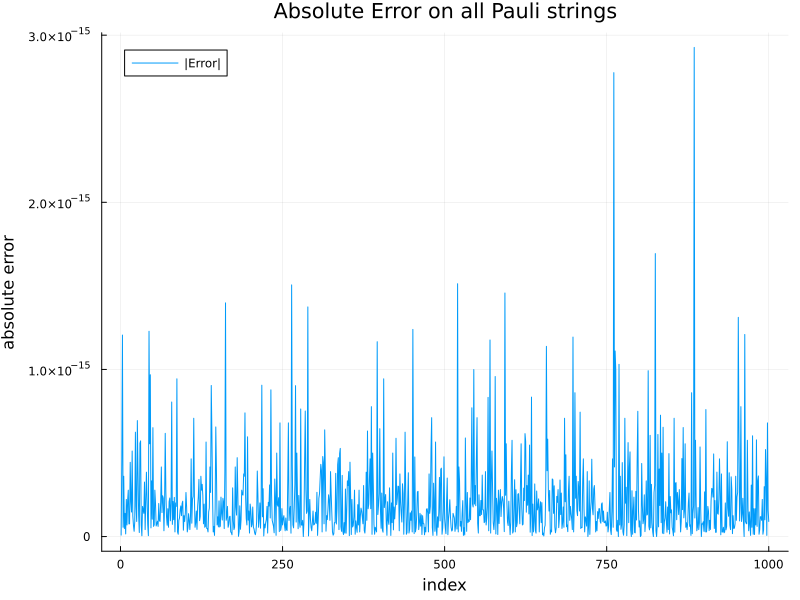

In [9]:
phis = [x->x[i] for i in 1:N] # Basic pre-processing function which picks k'th element of input vector.
t = make_basis_vectors(ωss, phis)


tt        = TCI.TensorTrain(tci)
cores_F   = TCI.sitetensors(tt)
cores_C   = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)
relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=2000, seed=113)

# p_random, y_true_rand, y_hat_rand, Phis_rand = compare_and_plot(fq, cores_C, t, Len; M=60, seed=123)
# display(p_random)
# savefig(p_random, "random_comparison_plot_$(maxbonddim).png")


maxdim = maximum(TCI.linkdims(tci))
# Use `ProfileCanvas.view()` for an interactive flamegraph after running this block if desired.
#savepath = "/Figs/Observables/N=$N,chi=$maxdim.png"
xs_per_pos =[[0,2π/3, 4π/3] for _ in 1:N]
fq_noisy = x -> fq_sampled(x,M)
p_grid, y_true_grid, y_hat_grid, grid_combinations, mean_abs_err = compare_on_grid_points(fq, cores_C,t, xs_per_pos;savepath = nothing)
display(p_grid)



In [47]:
println(fq([0,0,2π/3,0,0,0,2π/3,0]))
fq_sampled([0,0,2π/3,0,0,0,2π/3,0], 10000000)

0.0011977693194687791


0.0013472


=== BEGIN N = 6 ===
rank(tci)  = 16
Comparing on 1000 grid points...
Grid comparison results:
  RMSE = 1.6958129138679743e-16
  Max |error| = 6.661338147750939e-16
  Max rel |error| = 2.0991247151170045e-13
  Mean |error| = 1.246355042826622e-16
rank(tci)  = 16
Comparing on 1000 grid points...
Grid comparison results:
  RMSE = 2.080902296851957e-16
  Max |error| = 1.1102230246251565e-15
  Max rel |error| = 1.0584250743513128e-12
  Mean |error| = 1.5166696837234234e-16
rank(tci)  = 16
Comparing on 1000 grid points...
Grid comparison results:
  RMSE = 1.9290437563022314e-16
  Max |error| = 1.2212453270876722e-15
  Max rel |error| = 1.068207572276569e-12
  Mean |error| = 1.2665573884823589e-16
rank(tci)  = 16
Comparing on 1000 grid points...
Grid comparison results:
  RMSE = 1.9192499178444373e-16
  Max |error| = 8.881784197001252e-16
  Max rel |error| = 3.141947115705996e-13
  Mean |error| = 1.3850959225056303e-16
rank(tci)  = 16
Comparing on 1000 grid points...
Grid comparison results:

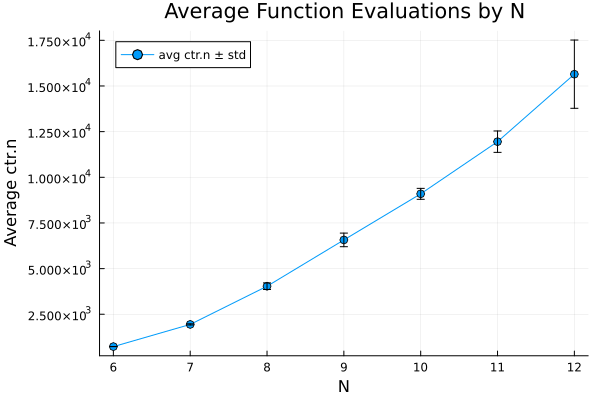

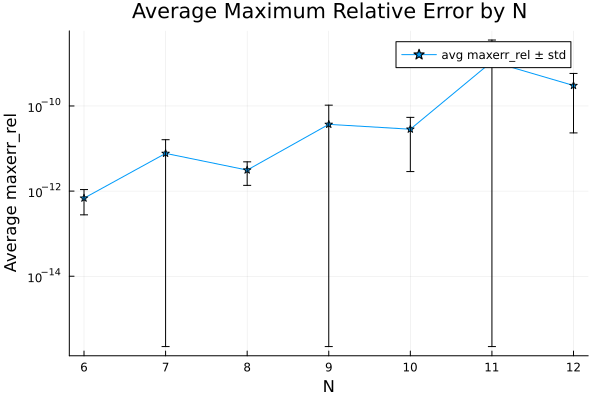

In [ ]:
"""clean version"""

using TensorCrossInterpolation
using Yao, Yao.ConstGate
using Statistics
import TensorCrossInterpolation as TCI

function TN_shadow_layer(N,x::AbstractVector)
    n = (1/sqrt(3))*(X+Y+Z)
    length(x) == N || error("V layer expects N parameters")
    chain([put(N, j=>rot(n, x[j])) for j=1:N]...)
end
###### Target function setting

Ns = 6:12
num_seeds = 5
maxbonddim = 16
tolerance = 1e-8
α = 2  # Integer
Zgate = Z  # Ensure Z is defined in the relevant context

avg_ctr_n_by_N = []
std_ctr_n_by_N = []
avg_maxerr_rel_by_N = []
std_maxerr_rel_by_N = []

for N in Ns
    println("\n=== BEGIN N = $N ===")
    Layer = 1
    Dks = 1  # number of frequencies per site for basis construction
    ωss = [[1] for _ in 1:N] # Should be known from the circuit

    V_list = [x -> TN_shadow_layer(N,x) for _ in 1:Layer]
    O = repeat(N, Zgate)
    gammas = gamma_vals(ωss)
    domain_range = 1 .+ (2*π ./ gammas)

    phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]
    M_sample = α .* phys_dims
    a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]
    a_vec_list = [[0.0, 2π/3, 4π/3] for k in 1:N]

    dims = [3 for _ in 1:N]

    ctr_n_list = Float64[]
    maxerr_rel_list = Float64[]

    for seed in 1:num_seeds
        # To ensure randomness in random_single_qubit_layer, set RNG seed
        Random.seed!(1000*N + seed)

        # Define W_list with different randomness each time
        W_list = [chain(
            random_single_qubit_layer(N),
            nearest_neighbor_cnot_layer(N),
            random_single_qubit_layer(N),
            nearest_neighbor_cnot_layer(N)
        )]

        fq, fq_sampled, _, _ = VQMLOracle.make_fq(N, Layer; W_list = W_list, V_list = V_list, O = O, seed = 7, init = :plus)

        # index → value wrapper for TCI
        f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N ])

        ctr = Counter(0, Dict{Tuple{Vararg{Int}},Float64}())
        f_cached = counted_unique(f_idx, ctr)

        tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch = :full, tolerance = tolerance, maxbonddim = maxbonddim
        )
        println("rank(tci)  = ", TCI.rank(tci))   

        # Prepare for comparison and error
        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)
        phis = [x -> x[i] for i in 1:N]
        t = make_basis_vectors(ωss, phis)
        cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)
        relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=2000, seed=113)

        xs_per_pos = [[0, 2π/3, 4π/3] for _ in 1:N]
        fq_noisy = x -> fq_sampled(x, M)
        _, _, _, _, maxerr_rel = compare_on_grid_points(fq, cores_C, t, xs_per_pos; savepath = nothing)

        push!(ctr_n_list, ctr.n)
        push!(maxerr_rel_list, maxerr_rel)
    end

    mean_ctr_n = mean(ctr_n_list)
    std_ctr_n = std(ctr_n_list)
    mean_maxerr_rel = mean(maxerr_rel_list)
    std_maxerr_rel = std(maxerr_rel_list)

    push!(avg_ctr_n_by_N, mean_ctr_n)
    push!(std_ctr_n_by_N, std_ctr_n)
    push!(avg_maxerr_rel_by_N, mean_maxerr_rel)
    push!(std_maxerr_rel_by_N, std_maxerr_rel)

    println("Results for N=$N: mean(ctr.n)=$(mean_ctr_n), std(ctr.n)=$(std_ctr_n), mean(maxerr_rel)=$(mean_maxerr_rel), std(maxerr_rel)=$(std_maxerr_rel)")
end

# Plot avg_ctr_n_by_N and avg_maxerr_rel_by_N vs N with error bars (std)
using Plots

# First plot: Average function evaluations by N (with errorbar)
p1 = Plots.plot(
    Ns, avg_ctr_n_by_N;
    yerror=std_ctr_n_by_N,
    marker=:o,
    xlabel="N",
    ylabel="Average ctr.n",
    title="Average Function Evaluations by N",
    label="avg ctr.n ± std"
)
savefig(p1, "Figs/Numerics/shallow_observable/avg_ctr_n_by_N.svg")
display(p1)

# Second plot: Average maximum relative error by N (log y axis, with errorbar)
p2 = Plots.plot(
    Ns, avg_maxerr_rel_by_N;
    yerror=std_maxerr_rel_by_N,
    marker=:s,
    xlabel="N",
    ylabel="Average maxerr_rel",
    title="Average Maximum Relative Error by N",
    label="avg maxerr_rel ± std",
    yaxis=:log10
)
savefig(p2, "Figs/Numerics/shallow_observable/avg_maxerr_rel_by_N.svg")
display(p2)


In [4]:
(17.5*10^4)/3^12


0.3292933740528111

In [ ]:
using TensorCrossInterpolation
using .VQMLOracle
using Yao, Yao.ConstGate
import TensorCrossInterpolation as TCI



##Sanity check block
###### Target function setting

N, L = 4, 1; Len = N*L
Dks = 1  # number of frequencies per site for basis construction
ωss = [[1] for _ in 1:N] # Should be known from the circuit


function TN_shadow_layer(N,x::AbstractVector)
    n = (1/sqrt(3))*(X+Y+Z)
    length(x) == N || error("V layer expects N parameters")
    chain([put(N, j=>rot(n, x[j])) for j=1:N]...)
end
V_list = [x ->TN_shadow_layer(N,x) for _ in 1:L]
O = repeat(N,Z)

gammas = gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]


phis = [x->x[i] for i in 1:Len] # Basic pre-processing function which picks k'th element of input vector.

t = make_basis_vectors(ωss, phis)

fq, W_list= VQMLOracle.make_fq(N, L;W_list = nothing,V_list =V_list,O=O,  seed=7, init=:plus)

#Check directly
H_all = chain([put(N, j=>H) for j=1:N]...)
ψ= apply(zero_state(N), H_all)
for ℓ in 1:L
    idxs = (ℓ-1)*N+1 : ℓ*N
    ψ = apply(ψ, W_list[ℓ])
end


O_block=repeat(N,Y)
O_block = chain(put(N, 1=>X), put(N, 2=>Y), put(N, 3=>Z), put(N, 4=>Y))
exp_val = real(expect( O_block, ψ))  

println("Direct",exp_val)
println("from circuit",fq([4π/3, 2π/3, 0, 2π/3]))


In [6]:
using TensorCrossInterpolation
using .VQMLOracle
using Yao, Yao.ConstGate
import TensorCrossInterpolation as TCI

###### Target function setting



function TN_shadow_layer(N,x::AbstractVector)
    n = (1/sqrt(3))*(X+Y+Z)
    length(x) == N || error("V layer expects N parameters")
    chain([put(N, j=>rot(n, x[j])) for j=1:N]...)
end


results = []

exp = 2  # Number of experiments per N; set exp to desired int

for N in 8:9
    for expt in 1:exp
        println("\n\n===============================")
        println("Running for N = $N (exp $expt / $exp)")
        println("===============================")

        ωss = [[1] for _ in 1:N]  # Should be known from the circuit

        O = repeat(N, Z)
        gammas = gamma_vals(ωss)
        domain_range = 1 .+ (2 * π ./ gammas)

        phys_dims = [2 * length(ωss[i]) + 1 for i in 1:length(ωss)]

        # Create V_list.W_list|+> circuit by setting L=1.
        Layer = 2

        # Use distinct random seed for each experiment to vary random circuits
        rand_seed = 42 + expt
        W_list = [chain(
            vcat( [ [random_single_qubit_layer(N), nearest_neighbor_cnot_layer(N)] for _ in 1:Layer]...)...
            )]

        L = 1
        V_list = [x -> TN_shadow_layer(N, x)]
        fq, W_list = VQMLOracle.make_fq(N, L; W_list = W_list, V_list = V_list, O = O, seed = rand_seed, init = :plus)

        # TCI grid
        a_vec_list = [[0.0, 2π / 3, 4π / 3] for k in 1:N]

        # Hyperparameters
        maxbonddim = 24
        tolerance = 1e-8

        # index → value wrapper for TCI
        f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])
        ctr = Counter(0, Dict{Tuple{Vararg{Int}}, Float64}())
        f_cached = counted_unique(f_idx, ctr)

        dims = [3 for _ in 1:N]

        tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch = :full, tolerance = tolerance, maxbonddim = maxbonddim
        )

        # TensorTrain analysis
        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)
        phis = [x -> x[i] for i in 1:N]
        t = make_basis_vectors(ωss, phis)
        cores_C = ttF_to_ttC(cores_F, ωss; auxs = a_vec_list)

        maxdim = maximum(TCI.linkdims(tci))

        xs_per_pos = [[0, 2π / 3, 4π / 3] for _ in 1:N]
        savepath = "./Figs/Observables/N=$(N),chi=$(maxdim),exp=$(expt).png"
        num_samp = 20000
        _, _, _, _, mean_abs_err = compare_on_grid_points(fq, cores_C, t, xs_per_pos; num_samp = num_samp, savepath = savepath)

        # Save stats to results
        push!(results, (N = N, expt = expt, ctr_n = ctr.n, mean_abs_err = mean_abs_err, maxdim = maxdim))

        println("For N = $N (exp $expt): function evals = $(ctr.n), mean_abs_err = $mean_abs_err, maxdim = $maxdim")
    end
end

println("\nSummary of results:")

for r in results
    println("N = $(r.N)  expt = $(r.expt)  ctr.n = $(r.ctr_n)  mean_abs_err = $(r.mean_abs_err)  maxdim = $(r.maxdim)")
end





Running for N = 8 (exp 1 / 2)
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 1.148607129615787e-16
  Max |error| = 9.43689570931383e-16
  Mean |error| = 7.936587218162426e-17
Saved plot → ./Figs/Observables/N=8,chi=16,exp=1.png
For N = 8 (exp 1): function evals = 3899, mean_abs_err = 7.936587218162426e-17, maxdim = 16


Running for N = 8 (exp 2 / 2)
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 1.485826053753022e-16
  Max |error| = 1.27675647831893e-15
  Mean |error| = 9.528658747574824e-17
Saved plot → ./Figs/Observables/N=8,chi=16,exp=2.png
For N = 8 (exp 2): function evals = 4185, mean_abs_err = 9.528658747574824e-17, maxdim = 16


Running for N = 9 (exp 1 / 2)
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 8.2085806210874e-17
  Max |error| = 7.216449660063518e-16
  Mean |error| = 4.937665838936944e-17
Saved plot → ./Figs/Observables/N=9,chi=16,exp=1.png


┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


For N = 9 (exp 1): function evals = 6733, mean_abs_err = 4.937665838936944e-17, maxdim = 16


Running for N = 9 (exp 2 / 2)
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 1.2277765530304683e-16
  Max |error| = 1.2212453270876722e-15
  Mean |error| = 7.653799943159086e-17
Saved plot → ./Figs/Observables/N=9,chi=16,exp=2.png
For N = 9 (exp 2): function evals = 6509, mean_abs_err = 7.653799943159086e-17, maxdim = 16

Summary of results:
N = 8  expt = 1  ctr.n = 3899  mean_abs_err = 7.936587218162426e-17  maxdim = 16
N = 8  expt = 2  ctr.n = 4185  mean_abs_err = 9.528658747574824e-17  maxdim = 16
N = 9  expt = 1  ctr.n = 6733  mean_abs_err = 4.937665838936944e-17  maxdim = 16
N = 9  expt = 2  ctr.n = 6509  mean_abs_err = 7.653799943159086e-17  maxdim = 16


In [ ]:
using Random
using Statistics
using Plots

mkpath("./Figs/Observables")

ntrials = 5
results_raw = NamedTuple[]   # (N, trial, ctr_n, mean_abs_err, maxdim)

for N in 10:16
    println("\n\n===============================")
    println("Running for N = $N")
    println("===============================")

    for trial in 1:ntrials
        seed = 42 + 1000*trial + N
        Random.seed!(seed)  # makes random_* layers change per trial

        ωss = [[1] for _ in 1:N]

        O = repeat(N, Z)
        gammas = gamma_vals(ωss)
        domain_range = 1 .+ (2*π ./ gammas)
        phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]

        Layer = 2
        W_list = [chain(
            vcat([ [random_single_qubit_layer(N), nearest_neighbor_cnot_layer(N)]
                  for _ in 1:Layer ]...)...
        )]

        L = 1
        V_list = [x -> TN_shadow_layer(N, x)]
        fq, W_list = VQMLOracle.make_fq(
            N, L; W_list=W_list, V_list=V_list, O=O, seed=seed, init=:plus
        )

        a_vec_list = [[0.0, 2π/3, 4π/3] for _ in 1:N]

        maxbonddim = 24
        tolerance = 1e-8

        f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])
        ctr = Counter(0, Dict{Tuple{Vararg{Int}},Float64}())
        f_cached = counted_unique(f_idx, ctr)

        dims = fill(3, N)
        tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch=:full, tolerance=tolerance, maxbonddim=maxbonddim
        )

        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)
        phis = [x -> x[i] for i in 1:N]
        t = make_basis_vectors(ωss, phis)
        cores_C = ttF_to_ttC(cores_F, ωss; auxs=a_vec_list)

        maxdim = maximum(TCI.linkdims(tci))

        xs_per_pos = [[0, 2π/3, 4π/3] for _ in 1:N]
        savepath = "./Figs/Observables/N=$(N),trial=$(trial),chi=$(maxdim).png"
        num_samp = 20000
        _, _, _, _, mean_abs_err = compare_on_grid_points(
            fq, cores_C, t, xs_per_pos; num_samp=num_samp, savepath=savepath
        )

        push!(results_raw, (N=N, trial=trial, ctr_n=ctr.n, mean_abs_err=mean_abs_err, maxdim=maxdim))
        println("trial=$trial seed=$seed: ctr.n=$(ctr.n), mean_abs_err=$mean_abs_err, maxdim=$maxdim")
    end
end

# --- average over trials for each N ---
Ns = sort!(unique([r.N for r in results_raw]))

avg_results = NamedTuple[]
for N in Ns
    rs = filter(r -> r.N == N, results_raw)
    push!(avg_results, (
        N = N,
        ctr_n = mean([r.ctr_n for r in rs]),
        mean_abs_err = mean([r.mean_abs_err for r in rs]),
        maxdim = mean([r.maxdim for r in rs]),
    ))
end

println("\nAveraged (over $ntrials trials):")
for r in avg_results
    println("N=$(r.N)  avg ctr.n=$(r.ctr_n)  avg mean_abs_err=$(r.mean_abs_err)  avg maxdim=$(r.maxdim)")
end







Running for N = 10
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 6.556492784711789e-17
  Max |error| = 9.159339953157541e-16
  Mean |error| = 3.9470895217105574e-17
Saved plot → ./Figs/Observables/N=10,trial=1,chi=16.png
trial=1 seed=1052: ctr.n=8520, mean_abs_err=3.9470895217105574e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 7.512851167767338e-17
  Max |error| = 1.1657341758564144e-15
  Mean |error| = 4.651272069904558e-17
Saved plot → ./Figs/Observables/N=10,trial=2,chi=16.png
trial=2 seed=2052: ctr.n=9239, mean_abs_err=4.651272069904558e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 7.970877041349644e-17
  Max |error| = 9.43689570931383e-16
  Mean |error| = 5.1025794421252295e-17
Saved plot → ./Figs/Observables/N=10,trial=3,chi=16.png
trial=3 seed=3052: ctr.n=9135, mean_abs_err=5.1025794421252295e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 3.31225

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


trial=3 seed=3053: ctr.n=11470, mean_abs_err=3.1099409828789004e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 5.4721214879554765e-17
  Max |error| = 9.43689570931383e-16
  Mean |error| = 3.1510797957267005e-17
Saved plot → ./Figs/Observables/N=11,trial=4,chi=16.png
trial=4 seed=4053: ctr.n=12175, mean_abs_err=3.1510797957267005e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 6.329242605224747e-17
  Max |error| = 6.938893903907228e-16
  Mean |error| = 4.079150295368814e-17
Saved plot → ./Figs/Observables/N=11,trial=5,chi=16.png


┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


trial=5 seed=5053: ctr.n=11473, mean_abs_err=4.079150295368814e-17, maxdim=16


Running for N = 12
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 4.9932179355544275e-17
  Max |error| = 6.522560269672795e-16
  Mean |error| = 3.037959675781216e-17
Saved plot → ./Figs/Observables/N=12,trial=1,chi=16.png


┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


... (28 outputs left out)

trial=4 seed=4058: ctr.n=24714, mean_abs_err=1.2193365683066863e-17, maxdim=16
Comparing on 20000 grid points...
Grid comparison results:
  RMSE = 1.953863468416704e-17
  Max |error| = 3.7470027081099033e-16
  Mean |error| = 1.1924854288409103e-17
Saved plot → ./Figs/Observables/N=16,trial=5,chi=16.png


┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


trial=5 seed=5058: ctr.n=26153, mean_abs_err=1.1924854288409103e-17, maxdim=16

Averaged (over 5 trials):
N=10  avg ctr.n=8993.2  avg mean_abs_err=4.1054977567723416e-13  avg maxdim=16.0
N=11  avg ctr.n=11475.4  avg mean_abs_err=3.792548445374041e-17  avg maxdim=16.0
N=12  avg ctr.n=14591.0  avg mean_abs_err=3.270480634956037e-17  avg maxdim=16.0
N=13  avg ctr.n=16831.2  avg mean_abs_err=3.0138812469759e-17  avg maxdim=16.0
N=14  avg ctr.n=20010.2  avg mean_abs_err=1.6652682121461727e-17  avg maxdim=16.0
N=15  avg ctr.n=23809.0  avg mean_abs_err=1.3940770191923244e-17  avg maxdim=16.0
N=16  avg ctr.n=26402.0  avg mean_abs_err=1.176069099455662e-17  avg maxdim=16.0


UndefVarError: UndefVarError: `plot` not defined in `Main`
Hint: It looks like two or more modules export different bindings with this name, resulting in ambiguity. Try explicitly importing it from a particular module, or qualifying the name with the module it should come from.
Hint: a global variable of this name also exists in YaoPlots.
Hint: a global variable of this name also exists in Yao.
Hint: a global variable of this name also exists in Plots.

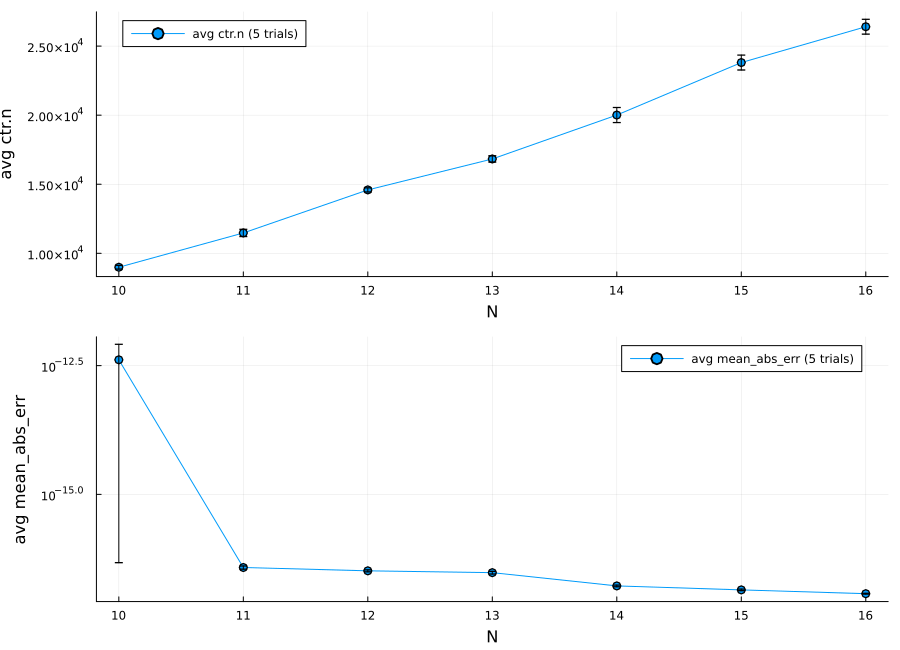

In [14]:
# --- plot averaged ctr.n and mean_abs_err vs N, with 1 std error bar ---

# Gather data for error bars by N
ctr_n_dict = Dict{Int, Vector{Float64}}()
err_n_dict = Dict{Int, Vector{Float64}}()
for r in results_raw
    push!(get!(ctr_n_dict, r.N, Float64[]), r.ctr_n)
    push!(get!(err_n_dict, r.N, Float64[]), r.mean_abs_err)
end

Ns_plot = sort(collect(keys(ctr_n_dict)))
ctr_plot = [mean(ctr_n_dict[N]) for N in Ns_plot]
ctr_std = [std(ctr_n_dict[N]) / sqrt(length(ctr_n_dict[N])) for N in Ns_plot]

err_plot = [mean(err_n_dict[N]) for N in Ns_plot]
err_std = [std(err_n_dict[N]) / sqrt(length(err_n_dict[N])) for N in Ns_plot]

p1 = Plots.plot(
    Ns_plot, ctr_plot; yerror=ctr_std, marker=:o, xlabel="N", ylabel="avg ctr.n",
    label="avg ctr.n (5 trials)"
)
p2 = Plots.plot(
    Ns_plot, err_plot; yerror=err_std, marker=:o, xlabel="N", ylabel="avg mean_abs_err",
    label="avg mean_abs_err (5 trials)", yscale=:log10
)  # drop yscale if you want linear

p = Plots.plot(p1, p2, layout=(2,1), size=(900,650))
savefig(p, "./Figs/Observables/avg_summary_ctr_err.png")
p